IRIS renseignés : 2018 = 18, 2021 = 18


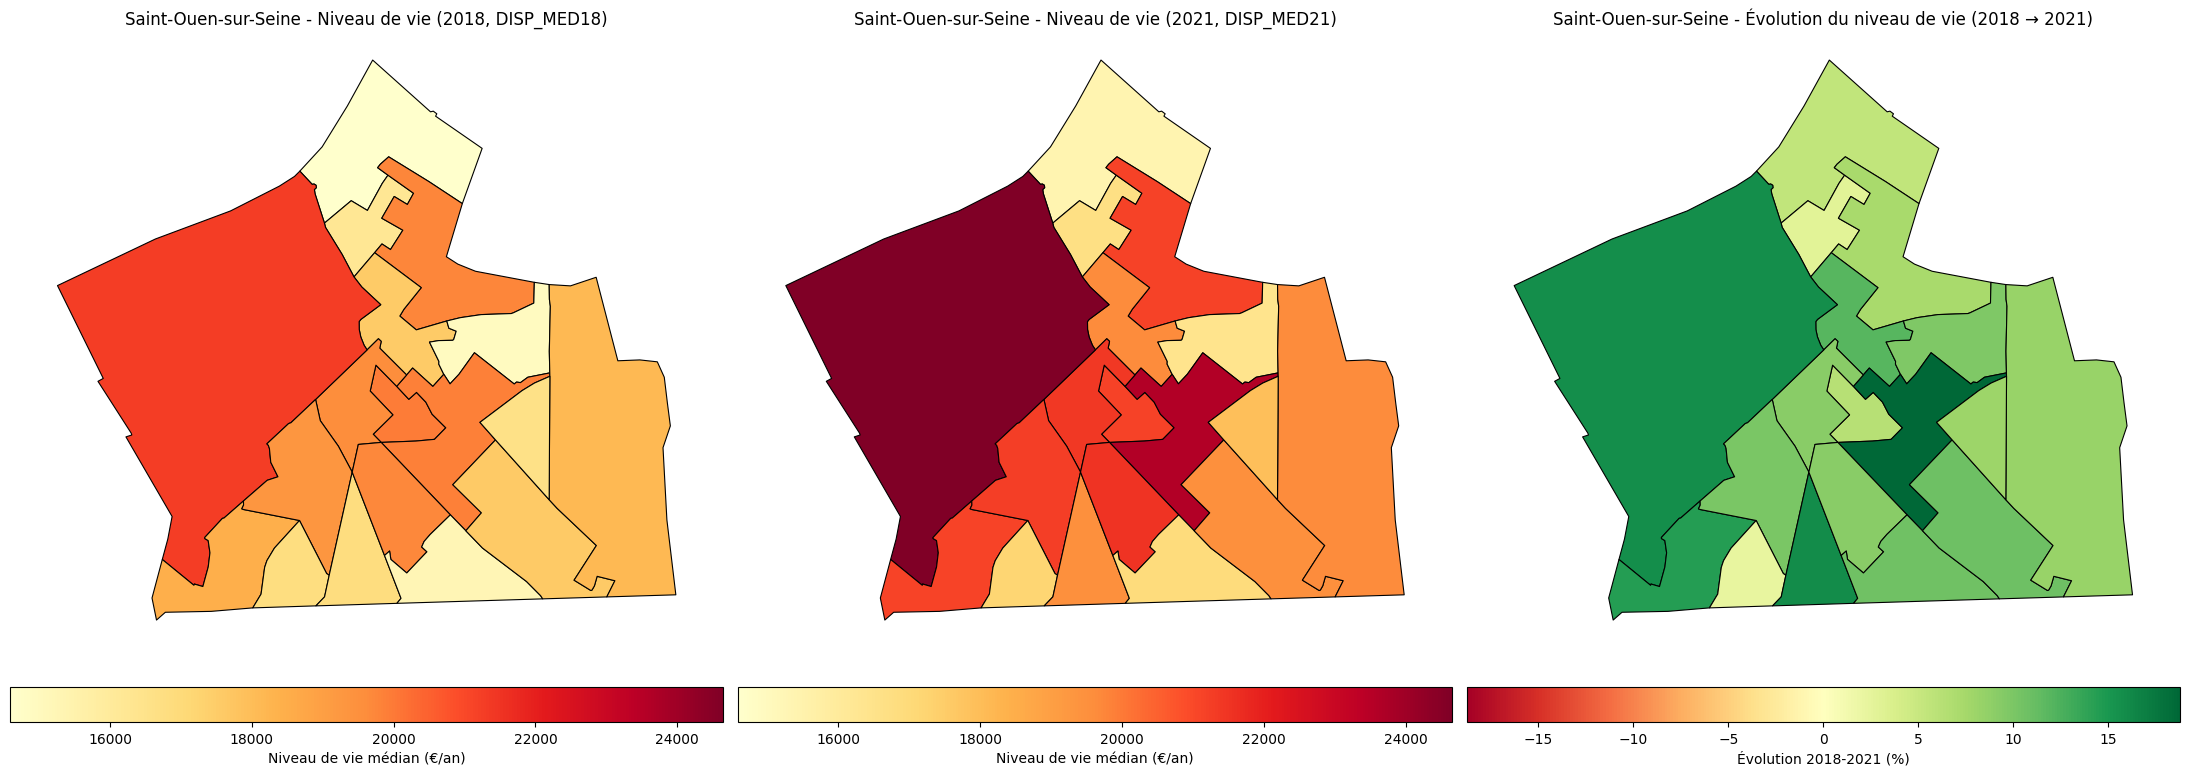

In [9]:
from pathlib import Path
from urllib.parse import urlencode
import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import pandas as pd
import requests

# Définition des dossiers (avec repli automatique si le dossier OneDrive n'existe pas)
dossier_script = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
dossier_onedrive = Path(
    "C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/projet_python_2a_ensae"
)
dossier_projet = dossier_onedrive if dossier_onedrive.exists() else dossier_script
dossier_parent = dossier_projet.parent
cache_filo_path = dossier_projet / "cache_saint_ouen_filo.pkl"


def _requete_wfs(bbox: str | None = None) -> gpd.GeoDataFrame:
    params = {
        "SERVICE": "WFS",
        "VERSION": "2.0.0",
        "REQUEST": "GetFeature",
        "TYPENAME": "STATISTICALUNITS.IRIS:contours_iris",
        "OUTPUTFORMAT": "application/json",
        "SRSNAME": "EPSG:4326",
        "COUNT": "500",
    }
    if bbox is not None:
        params["BBOX"] = bbox
    url = f"https://data.geopf.fr/wfs/ows?{urlencode(params)}"
    return gpd.read_file(url)


def charger_iris_wfs(commune_prefix: str = "93070") -> tuple[gpd.GeoDataFrame, str]:
    """Récupère les contours IRIS via l'API WFS IGN autour de Saint-Ouen."""
    candidats_bbox = [
        "2.310,48.895,2.360,48.925,urn:ogc:def:crs:EPSG::4326",
        "48.895,2.310,48.925,2.360,urn:ogc:def:crs:EPSG::4326",
        None,
    ]

    gdf = gpd.GeoDataFrame()
    for bbox in candidats_bbox:
        try:
            gdf_tmp = _requete_wfs(bbox)
            if not gdf_tmp.empty:
                gdf = gdf_tmp
                break
        except Exception:
            continue

    if gdf.empty:
        raise RuntimeError(
            "Le service WFS n'a renvoyé aucune entité IRIS. Vérifiez votre connexion ou les couches via GetCapabilities."
        )

    cols_non_geom = [c for c in gdf.columns if c != gdf.geometry.name]

    colonnes_prioritaires = ["code_iris", "CODE_IRIS", "iris", "IRIS", "id_iris"]
    col_geo_code = next(
        (
            col
            for col in colonnes_prioritaires
            if col in cols_non_geom
            and gdf[col]
            .dropna()
            .astype(str)
            .str.strip()
            .str.startswith(commune_prefix)
            .any()
        ),
        None,
    )

    if col_geo_code is None:
        col_geo_code = next(
            (
                col
                for col in cols_non_geom
                if gdf[col]
                .dropna()
                .astype(str)
                .str.strip()
                .str.startswith(commune_prefix)
                .any()
            ),
            None,
        )

    if col_geo_code is None:
        raise ValueError(
            f"Impossible d'identifier la colonne code IRIS parmi : {cols_non_geom}"
        )

    gdf_commune = gdf[
        gdf[col_geo_code].astype(str).str.strip().str.startswith(commune_prefix)
    ].copy()
    gdf_commune[col_geo_code] = (
        gdf_commune[col_geo_code].astype(str).str.strip().str.zfill(9)
    )
    return gdf_commune, col_geo_code


def _extraire_observations_melodi(payload: dict) -> list[dict]:
    """Aplatit les observations renvoyées par l'API Melodi /data/{id}."""
    observations = payload.get("observations") or payload.get("data") or []
    lignes = []
    for obs in observations:
        if not isinstance(obs, dict):
            continue
        ligne = {}
        dims = obs.get("dimensions")
        if isinstance(dims, dict):
            for k, v in dims.items():
                ligne[k] = v.get("code") if isinstance(v, dict) else v
        measures = obs.get("measures")
        if isinstance(measures, dict):
            for k, v in measures.items():
                ligne[k] = v.get("value") if isinstance(v, dict) else v
        for k, v in obs.items():
            if k not in ("dimensions", "measures", "attributes"):
                ligne[k] = v.get("value") if isinstance(v, dict) else v
        lignes.append(ligne)
    return lignes


def charger_filosofi_melodi(
    commune_prefix: str = "93070", force_reload: bool = False
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Charge les données Filosofi 2018 et 2021 via l'API Melodi de l'INSEE."""
    if cache_filo_path.exists() and not force_reload:
        data = pd.read_pickle(cache_filo_path)
        return data["df_2018"], data["df_2021"]

    base_url = "https://api.insee.fr/melodi"
    cat_resp = requests.get(f"{base_url}/catalog/all", timeout=30)
    cat_resp.raise_for_status()
    catalogue = cat_resp.json()
    datasets = catalogue if isinstance(catalogue, list) else catalogue.get("datasets", [])

    candidats_ids = []
    for ds in datasets:
        texte = str(ds).lower()
        if "filosofi" in texte or "filo" in texte:
            ds_id = ds.get("id") or ds.get("identifier")
            if ds_id:
                candidats_ids.append(ds_id)

    if not candidats_ids:
        raise RuntimeError(
            "Aucun jeu de données Filosofi trouvé dans le catalogue Melodi via /catalog/all."
        )

    lignes_2018 = []
    lignes_2021 = []

    for ds_id in candidats_ids:
        data_resp = requests.get(
            f"{base_url}/data/{ds_id}", params={"maxResult": 10000}, timeout=30
        )
        if data_resp.status_code != 200:
            continue
        obs_lignes = _extraire_observations_melodi(data_resp.json())
        for row in obs_lignes:
            row_str = {str(k).upper(): v for k, v in row.items()}
            iris_val = next(
                (
                    str(row_str[c]).strip()
                    for c in ("IRIS", "GEO", "TERRITOIRE", "CODE_IRIS", "AREA")
                    if c in row_str and row_str[c] is not None
                ),
                "",
            )
            iris_code = iris_val.replace("IRIS-", "").split(".")[0].zfill(9)
            if not iris_code.startswith(commune_prefix):
                continue

            annee = str(
                row_str.get("TIME_PERIOD")
                or row_str.get("ANNEE")
                or row_str.get("MILLESIME")
                or ""
            )
            val = next(
                (
                    row_str[c]
                    for c in ("OBS_VALUE", "VALUE", "DISP_MED", "DISP_MED18", "DISP_MED21")
                    if c in row_str and row_str[c] is not None
                ),
                None,
            )
            if "2018" in annee or "18" in str(row_str.get("INDICATOR", "")):
                lignes_2018.append({"IRIS": iris_code, "DISP_MED18": val})
            elif "2021" in annee or "21" in str(row_str.get("INDICATOR", "")):
                lignes_2021.append({"IRIS": iris_code, "DISP_MED21": val})

    if not lignes_2018 and not lignes_2021:
        raise RuntimeError(
            f"Jeux candidats Melodi testés ({candidats_ids}), mais aucune observation IRIS 2018/2021 n'a été extraite."
        )

    df_2018 = pd.DataFrame(lignes_2018)
    if df_2018.empty:
        df_2018 = pd.DataFrame(columns=["IRIS", "DISP_MED18"])
    df_2018["IRIS"] = (
        df_2018["IRIS"].astype(str).str.split(".").str[0].str.strip().str.zfill(9)
    )
    df_2018["DISP_MED18"] = pd.to_numeric(df_2018["DISP_MED18"], errors="coerce")

    df_2021 = pd.DataFrame(lignes_2021)
    if df_2021.empty:
        df_2021 = pd.DataFrame(columns=["IRIS", "DISP_MED21"])
    df_2021["IRIS"] = (
        df_2021["IRIS"].astype(str).str.split(".").str[0].str.strip().str.zfill(9)
    )
    df_2021["DISP_MED21"] = pd.to_numeric(df_2021["DISP_MED21"], errors="coerce")

    pd.to_pickle({"df_2018": df_2018, "df_2021": df_2021}, cache_filo_path)
    return df_2018, df_2021


# 1. Charger les contours IRIS de Saint-Ouen (93070) via l'API WFS IGN
st_ouen_iris, col_geo_code = charger_iris_wfs("93070")

# 2 & 3. Charger les données Filosofi 2018 et 2021 depuis Melodi
df_2018, df_2021 = charger_filosofi_melodi("93070")

col_iris_2018, col_niv_2018 = "IRIS", "DISP_MED18"
col_iris_2021, col_niv_2021 = "IRIS", "DISP_MED21"

st_ouen_2018 = st_ouen_iris.merge(
    df_2018, left_on=col_geo_code, right_on=col_iris_2018, how="left"
)
st_ouen_2021 = st_ouen_iris.merge(
    df_2021, left_on=col_geo_code, right_on=col_iris_2021, how="left"
)

nb_valides_2018 = st_ouen_2018[col_niv_2018].notna().sum()
nb_valides_2021 = st_ouen_2021[col_niv_2021].notna().sum()
print(f"IRIS renseignés : 2018 = {nb_valides_2018}, 2021 = {nb_valides_2021}")
if nb_valides_2018 == 0 and nb_valides_2021 == 0:
    raise ValueError(
        f"Aucune correspondance entre WFS ({st_ouen_iris[col_geo_code].unique()[:5]}) "
        f"et Melodi 2018 ({df_2018[col_iris_2018].head().tolist()})."
    )

# 4. Calculer l'évolution 2018 -> 2021 par quartier IRIS
st_ouen_evol = st_ouen_iris.merge(
    df_2018[[col_iris_2018, col_niv_2018]].rename(columns={col_niv_2018: "niv_2018"}),
    left_on=col_geo_code,
    right_on=col_iris_2018,
    how="left",
).merge(
    df_2021[[col_iris_2021, col_niv_2021]].rename(columns={col_niv_2021: "niv_2021"}),
    left_on=col_geo_code,
    right_on=col_iris_2021,
    how="left",
)

st_ouen_evol["evol_pct"] = (
    (st_ouen_evol["niv_2021"] - st_ouen_evol["niv_2018"])
    / st_ouen_evol["niv_2018"]
* 100
)

# 5. Générer les trois cartes côte à côte
vmin = min(st_ouen_2018[col_niv_2018].min(), st_ouen_2021[col_niv_2021].min())
vmax = max(st_ouen_2018[col_niv_2018].max(), st_ouen_2021[col_niv_2021].max())

max_abs_evol = max(
    abs(st_ouen_evol["evol_pct"].min()), abs(st_ouen_evol["evol_pct"].max())
)
norm_evol = mcolors.TwoSlopeNorm(vmin=-max_abs_evol, vcenter=0, vmax=max_abs_evol)

fig, axes = plt.subplots(1, 3, figsize=(22, 8))

# Carte 1 : 2018
st_ouen_2018.plot(
    ax=axes[0],
    column=col_niv_2018,
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Niveau de vie médian (€/an)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
)
axes[0].set_title(
    f"Saint-Ouen-sur-Seine - Niveau de vie (2018, {col_niv_2018})", fontsize=12
)
axes[0].axis("off")

# Carte 2 : 2021
st_ouen_2021.plot(
    ax=axes[1],
    column=col_niv_2021,
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Niveau de vie médian (€/an)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
)
axes[1].set_title(
    f"Saint-Ouen-sur-Seine - Niveau de vie (2021, {col_niv_2021})", fontsize=12
)
axes[1].axis("off")

# Carte 3 : Évolution (%) 2018 -> 2021
st_ouen_evol.plot(
    ax=axes[2],
    column="evol_pct",
    cmap="RdYlGn",
    norm=norm_evol,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Évolution 2018-2021 (%)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
)
axes[2].set_title(
    "Saint-Ouen-sur-Seine - Évolution du niveau de vie (2018 → 2021)", fontsize=12
)
axes[2].axis("off")

plt.tight_layout()
plt.show()

Chargement des contours des quartiers...


C:\Users\pauli_ubewzsu\AppData\Local\Temp\ipykernel_17988\4012721659.py:104: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["part_cadres"] = (df[col_cadres] / df[col_total]) * 100
c:\Users\pauli_ubewzsu\OneDrive\Bureau\python 2a\.venv\lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\pauli_ubewzsu\AppData\Local\Temp\ipykernel_17988\4012721659.py:136: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["mixité_sociale"] = 

Fusion réussie -> IRIS 2011 : 18 | IRIS 2021 : 18


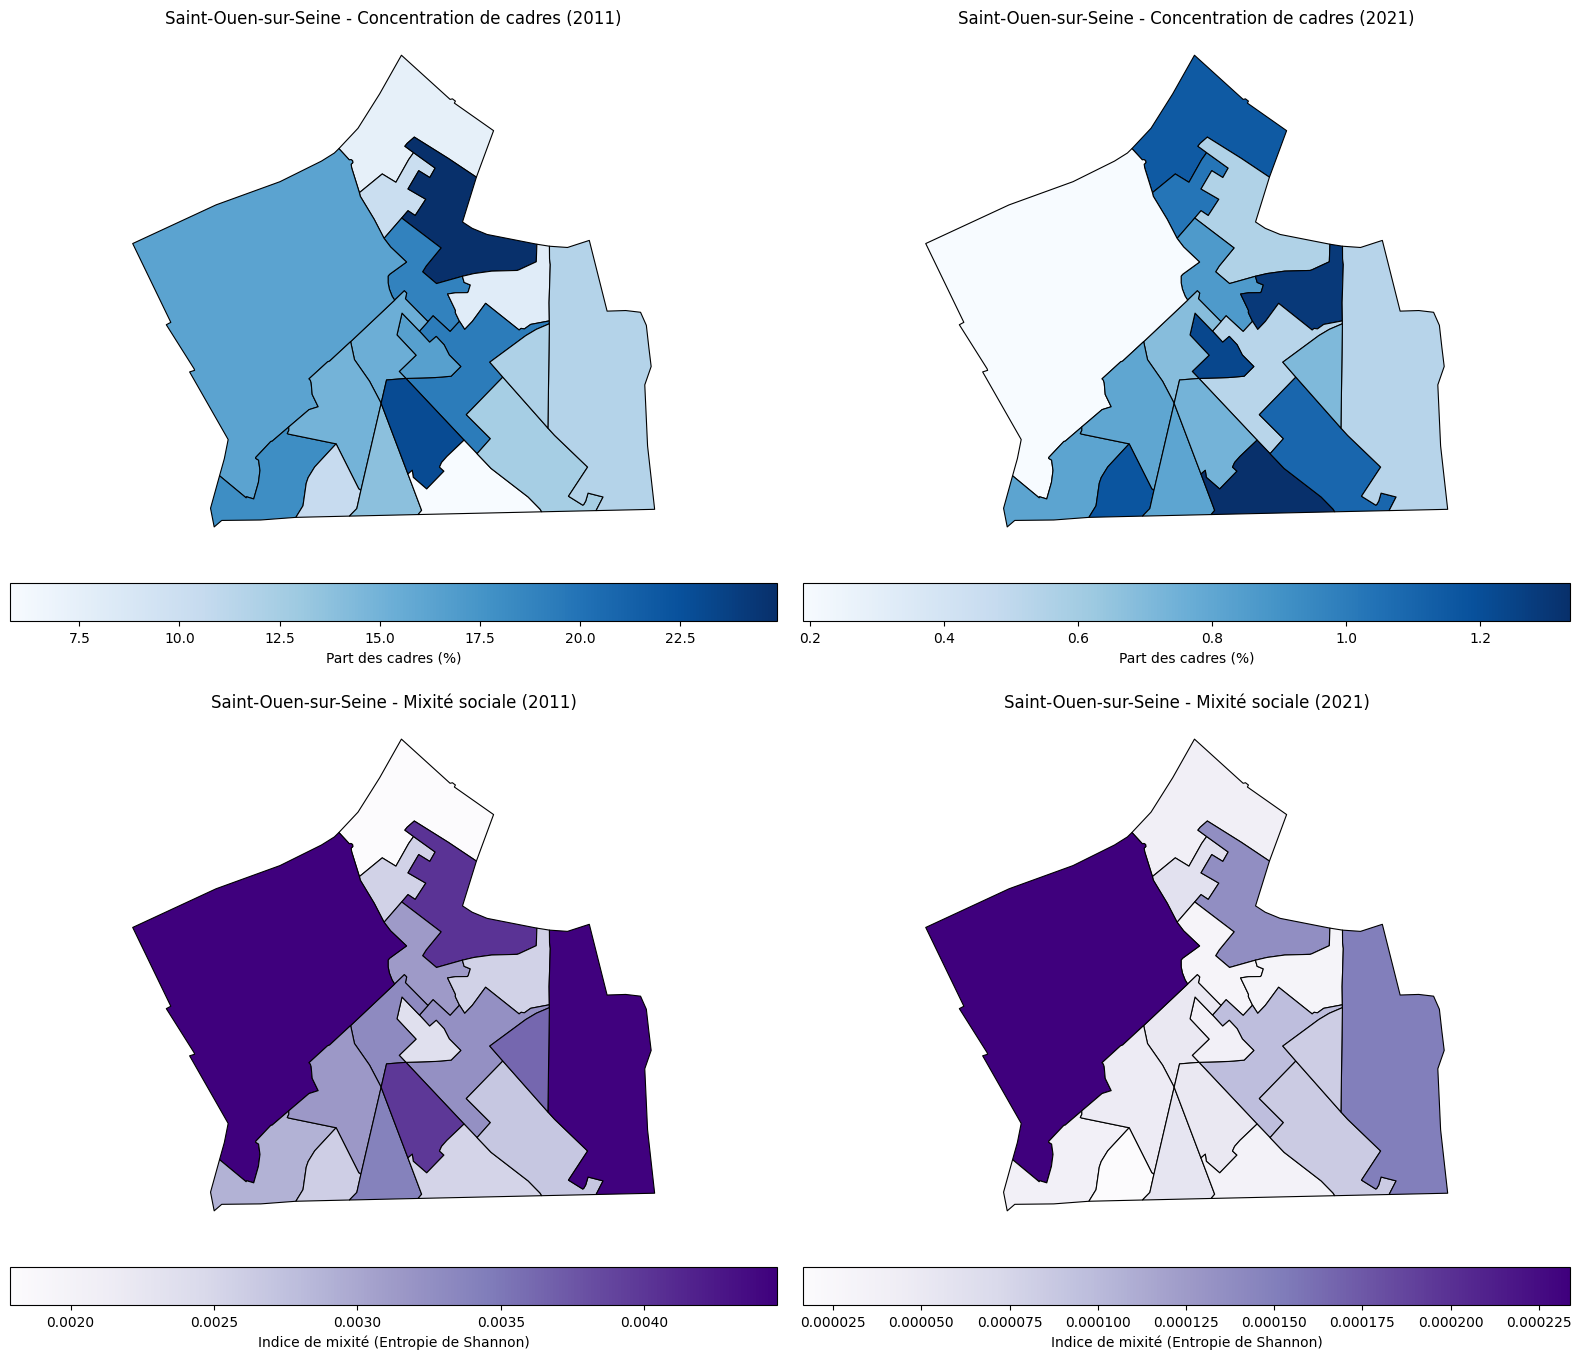

In [29]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CHARGEMENT ET PRÉPARATION DU FONDS DE CARTE (SAINT-OUEN)
# ==============================================================================
print("Chargement des contours des quartiers...")
iris_all = gpd.read_file(
    "C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/projet_python_2a_ensae/iris.gpkg"
)

# Trouver la colonne géographique
col_geo_code = None
for col in iris_all.columns:
  sample = iris_all[col].astype(str).str.strip()
  if (sample.str.len() == 9).any() and sample.str.startswith("93").any():
    col_geo_code = col
    break

if col_geo_code is None:
  for c in ["CODE_IRIS", "IRIS", "code", "DCODiIRIS"]:
    if c in iris_all.columns:
      col_geo_code = c
      break

# Filtrer Saint-Ouen-sur-Seine (Code INSEE 93070)
st_ouen_iris = iris_all[
    iris_all[col_geo_code].astype(str).str.strip().str.startswith("93070")
].copy()

# Création d'une clé textuelle propre sur 9 caractères pour le fonds de carte
st_ouen_iris["merge_key"] = (
    st_ouen_iris[col_geo_code]
    .astype(str)
    .str.split(".")
    .str[0]
    .str.strip()
    .str.zfill(9)
)


# ==============================================================================
# 2. CHARGEMENT ET NETTOYAGE DES DONNÉES INFORMATIVES (CSP 2011 & 2021)
# ==============================================================================
file_2011 = "C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/base-ic-activite-residents-2011.xls"
file_2021 = "C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/base-ic-activite-residents-2022.xlsx"

df_2011 = pd.read_excel(file_2011, skiprows=5)
df_2021 = pd.read_excel(file_2021, skiprows=5)

# Normalisation et création de la même clé textuelle pour les tableaux INSEE
for df in [df_2011, df_2021]:
  col_iris_name = next(
      (c for c in df.columns if "IRIS" in c.upper() or "CODE" in c.upper()),
      df.columns[0],
  )
  df["merge_key"] = (
      df[col_iris_name]
      .astype(str)
      .str.split(".")
      .str[0]
      .str.strip()
      .str.zfill(9)
  )


# ==============================================================================
# 3. CALCUL DES INDICATEURS (Part des cadres & Indice de Shannon)
# ==============================================================================
def preparer_donnees_csp(df):
  cols_num = [c for c in df.columns if c != "merge_key"]
  for c in cols_num:
    df[c] = pd.to_numeric(df[c], errors="coerce")
  return df


df_2011 = preparer_donnees_csp(df_2011)
df_2021 = preparer_donnees_csp(df_2021)


def calcul_indicateurs(df):
  # Détection dynamique des colonnes clés de l'INSEE
  col_cadres = next(
      (
          c
          for c in df.columns
          if "CADRE" in c.upper() or "CS3" in c.upper()
      ),
      df.columns[1],
  )
  col_total = next(
      (
          c
          for c in df.columns
          if "ACT15P" in c.upper()
          or ("ACT" in c.upper() and "15" in c.upper())
      ),
      df.columns[3],
  )

  # 1. Calcul de la part des cadres (%)
  df["part_cadres"] = (df[col_cadres] / df[col_total]) * 100

  # 2. Calcul du véritable Indice de Mixité Sociale (Entropie de Shannon)
  csp_keywords = [
      "AGRI",
      "ART",
      "CADRE",
      "PROF",
      "EMP",
      "OUV",
      "CS1",
      "CS2",
      "CS3",
      "CS4",
      "CS5",
      "CS6",
  ]
  cols_csp = [
      c
      for c in df.columns
      if any(kw in c.upper() for kw in csp_keywords)
      and c != col_total
      and c != "merge_key"
  ]

  if len(cols_csp) >= 2:
    somme_csp = df[cols_csp].sum(axis=1).replace(0, np.nan)
    shannon_index = 0
    for c in cols_csp:
      p_i = df[c] / somme_csp
      # Formule de Shannon : - sum(p_i * ln(p_i))
      shannon_index -= np.where(p_i > 0, p_i * np.log(p_i), 0)
    df["mixité_sociale"] = shannon_index
  else:
    df["mixité_sociale"] = 0.0

  return df


df_2011 = calcul_indicateurs(df_2011)
df_2021 = calcul_indicateurs(df_2021)

# Fusion ultra-sécurisée via la clé commune 'merge_key'
st_ouen_2011 = st_ouen_iris.merge(df_2011, on="merge_key", how="inner")
st_ouen_2021 = st_ouen_iris.merge(df_2021, on="merge_key", how="inner")

print(
    f"Fusion réussie -> IRIS 2011 : {len(st_ouen_2011)} | IRIS 2021 :"
    f" {len(st_ouen_2021)}"
)


# ==============================================================================
# 4. GÉNÉRATION DES 4 CARTES (2x2)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# --- Carte 1 : Part des cadres (2011) ---
st_ouen_2011.plot(
    ax=axes[0, 0],
    column="part_cadres",
    cmap="Blues",
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Part des cadres (%)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
)
axes[0, 0].set_title(
    "Saint-Ouen-sur-Seine - Concentration de cadres (2011)", fontsize=12
)
axes[0, 0].axis("off")

# --- Carte 2 : Part des cadres (2021) ---
st_ouen_2021.plot(
    ax=axes[0, 1],
    column="part_cadres",
    cmap="Blues",
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Part des cadres (%)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
)
axes[0, 1].set_title(
    "Saint-Ouen-sur-Seine - Concentration de cadres (2021)", fontsize=12
)
axes[0, 1].axis("off")

# --- Carte 3 : Mixité sociale (2011) ---
st_ouen_2011.plot(
    ax=axes[1, 0],
    column="mixité_sociale",
    cmap="Purples",
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Indice de mixité (Entropie de Shannon)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
)
axes[1, 0].set_title(
    "Saint-Ouen-sur-Seine - Mixité sociale (2011)", fontsize=12
)
axes[1, 0].axis("off")

# --- Carte 4 : Mixité sociale (2021) ---
st_ouen_2021.plot(
    ax=axes[1, 1],
    column="mixité_sociale",
    cmap="Purples",
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Indice de mixité (Entropie de Shannon)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
)
axes[1, 1].set_title(
    "Saint-Ouen-sur-Seine - Mixité sociale (2021)", fontsize=12
)
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

In [28]:
# ==============================================================================
# 5. ÉVOLUTION 2011 - 2022 : JEUNES MÉNAGES SEULS & COUPLES SANS ENFANT JEUNES
#    (Base INSEE : Couples - Familles - Ménages)
# ==============================================================================
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

file_cfm_2011 = (
    "C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/base-ic-couples-familles-menages-2011.xls"
)
file_cfm_2022 = (
    "C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/base-ic-couples-familles-menages-2022.xlsx"
)


def trouver_colonne(df, candidats, mots_cles_fallback=None):
  cols_upper = {str(c).upper(): c for c in df.columns}
  # 1. Recherche exacte
  for cand in candidats:
    c_up = cand.upper()
    if c_up in cols_upper:
      return cols_upper[c_up]
  # 2. Recherche partielle
  for cand in candidats:
    c_up = cand.upper()
    for up, orig in cols_upper.items():
      if c_up in up:
        return orig
  # 3. Recherche souple par mots-clés
  if mots_cles_fallback:
    for up, orig in cols_upper.items():
      if all(k.upper() in up for k in mots_cles_fallback):
        return orig
  return None


def normaliser_code_iris(serie):
  return (
      serie.astype(str)
      .str.replace(r"\.0$", "", regex=True)
      .str.strip()
      .str.zfill(9)
  )


def preparer_fonds_carte_st_ouen(gdf):
  """Garantit la présence d'une colonne 'merge_key' propre sur le GeoDataFrame."""
  out = gdf.copy()
  if "merge_key" not in out.columns:
    col_iris = trouver_colonne(
        out,
        ["CODE_IRIS", "IRIS", "ID_IRIS", "DCOMIRIS", "CODE"],
        mots_cles_fallback=["IRIS"],
    )
    if col_iris is None:
      raise KeyError(
          f"Impossible de trouver la colonne IRIS dans st_ouen_iris. Colonnes disponibles : {list(out.columns)}"
      )
    print(f"Colonne IRIS détectée dans st_ouen_iris : '{col_iris}'")
    out["merge_key"] = normaliser_code_iris(out[col_iris])
  else:
    out["merge_key"] = normaliser_code_iris(out["merge_key"])
  return out.drop_duplicates(subset=["merge_key"], keep="first")


def charger_cfm(chemin_fichier):
  df = pd.read_excel(chemin_fichier, skiprows=5)
  col_iris_cfm = trouver_colonne(
      df,
      ["IRIS", "CODE_IRIS", "COM", "GEO"],
      mots_cles_fallback=["IRIS"],
  )
  if col_iris_cfm is None:
    col_iris_cfm = df.columns[0]

  df["merge_key"] = normaliser_code_iris(df[col_iris_cfm])
  for c in df.columns:
    if c != "merge_key":
      df[c] = pd.to_numeric(df[c], errors="coerce")
  return df.drop_duplicates(subset=["merge_key"], keep="first")


def preparer_indicateur_jeunes_menages(df, annee_court):
  """Calcule l'effectif et la part (%) des ménages jeunes seuls et couples sans enfant jeunes."""
  col_men_total = trouver_colonne(
      df,
      [f"C{annee_court}_MEN", "MEN", "P_MEN"],
      mots_cles_fallback=["MEN"],
  )
  if col_men_total is None:
    raise KeyError(
        f"Colonne total ménages introuvable pour {annee_court}. Colonnes : {list(df.columns[:15])}"
    )

  col_jeunes_seuls = trouver_colonne(
      df,
      [
          f"P{annee_court}_POP1524_PSEUL",
          f"C{annee_court}_MENPSEUL_1524",
          "POP1524_PSEUL",
          "MENPSEUL",
      ],
  )
  col_couples_sans_enf = trouver_colonne(
      df,
      [
          f"C{annee_court}_MENCOUPSENF",
          f"C{annee_court}_MEN1FCOUPSENF",
          "MENCOUPSENF",
          "COUPSENF",
      ],
  )
  col_couples_jeunes = trouver_colonne(
      df,
      [
          f"C{annee_court}_MENCOUPSENF_JEUNE",
          "COUPSENF_JEUNE",
          "COUPLE_JEUNE",
      ],
  )

  print(f"--- Colonnes détectées ({annee_court}) ---")
  print(f"  Total ménages        : {col_men_total}")
  print(f"  Jeunes seuls         : {col_jeunes_seuls}")
  print(
      f"  Couples sans enfant  : {col_couples_sans_enf} (spécifique jeune: {col_couples_jeunes})"
  )

  effectif_jeunes_seuls = (
      df[col_jeunes_seuls].fillna(0) if col_jeunes_seuls else 0.0
  )

  if col_couples_jeunes:
    effectif_couples = df[col_couples_jeunes].fillna(0)
  elif col_couples_sans_enf:
    col_pop_jeunes = trouver_colonne(df, [f"P{annee_court}_POP1524", "POP1524"])
    col_pop_tot = trouver_colonne(
        df, [f"P{annee_court}_POP15P", "POP15P", f"P{annee_court}_POP"]
    )
    if col_pop_jeunes and col_pop_tot:
      part_jeunes_pop = (
          df[col_pop_jeunes] / df[col_pop_tot].replace(0, np.nan)
      ).fillna(0)
      effectif_couples = df[col_couples_sans_enf].fillna(0) * part_jeunes_pop
    else:
      effectif_couples = df[col_couples_sans_enf].fillna(0)
  else:
    effectif_couples = 0.0

  out = pd.DataFrame({
      "merge_key": df["merge_key"],
      "nb_cible": effectif_jeunes_seuls + effectif_couples,
      "nb_men_total": df[col_men_total],
  })
  out["part_cible_pct"] = (
      out["nb_cible"] / out["nb_men_total"].replace(0, np.nan)
  ) * 100
  return out


st_ouen_clean = preparer_fonds_carte_st_ouen(st_ouen_iris)
cfm_2011 = charger_cfm(file_cfm_2011)
cfm_2022 = charger_cfm(file_cfm_2022)

ind_2011 = preparer_indicateur_jeunes_menages(cfm_2011, "11")
ind_2022 = preparer_indicateur_jeunes_menages(cfm_2022, "22")

# Fusion avec le fonds de carte de Saint-Ouen
evol_iris = (
    st_ouen_clean[["merge_key", "geometry"]]
    .merge(
        ind_2011[["merge_key", "nb_cible", "part_cible_pct"]].rename(
            columns={"nb_cible": "nb_2011", "part_cible_pct": "part_2011"}
        ),
        on="merge_key",
        how="left",
    )
    .merge(
        ind_2022[["merge_key", "nb_cible", "part_cible_pct"]].rename(
            columns={"nb_cible": "nb_2022", "part_cible_pct": "part_2022"}
        ),
        on="merge_key",
        how="left",
    )
)

# Évolution en points de pourcentage (2022 - 2011)
evol_iris["evol_pts"] = evol_iris["part_2022"] - evol_iris["part_2011"]

print(
    f"IRIS Saint-Ouen : {len(evol_iris)} | "
    f"Sans valeur 2011 : {evol_iris['part_2011'].isna().sum()} | "
    f"Sans valeur 2022 : {evol_iris['part_2022'].isna().sum()}"
)

# Bornes communes pour les cartes 2011 et 2022
vals_parts = pd.concat(
    [evol_iris["part_2011"], evol_iris["part_2022"]], ignore_index=True
).dropna()
vmin_part = float(vals_parts.min()) if not vals_parts.empty else 0.0
vmax_part = float(vals_parts.max()) if not vals_parts.empty else 10.0
if vmin_part == vmax_part:
  vmax_part = vmin_part + 1.0

# Borne symétrique autour de 0 pour la carte d'évolution
vmax_evol = np.nanmax(np.abs(evol_iris["evol_pts"]))
vmax_evol = float(vmax_evol) if pd.notna(vmax_evol) and vmax_evol > 0 else 5.0

fig_3cartes, axes = plt.subplots(1, 3, figsize=(22, 8))

# --- Carte 1 : 2011 ---
evol_iris.plot(
    ax=axes[0],
    column="part_2011",
    cmap="Oranges",
    vmin=vmin_part,
    vmax=vmax_part,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Part des ménages cibles (%)",
        "orientation": "horizontal",
        "pad": 0.04,
    },
)
axes[0].set_title(
    "Saint-Ouen-sur-Seine - 2011\n"
    "Ménages jeunes seuls & couples sans enfant jeunes",
    fontsize=12,
)
axes[0].axis("off")

# --- Carte 2 : 2022 ---
evol_iris.plot(
    ax=axes[1],
    column="part_2022",
    cmap="Oranges",
    vmin=vmin_part,
    vmax=vmax_part,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Part des ménages cibles (%)",
        "orientation": "horizontal",
        "pad": 0.04,
    },
)
axes[1].set_title(
    "Saint-Ouen-sur-Seine - 2022\n"
    "Ménages jeunes seuls & couples sans enfant jeunes",
    fontsize=12,
)
axes[1].axis("off")

# --- Carte 3 : Évolution 2022 - 2011 ---
evol_iris.plot(
    ax=axes[2],
    column="evol_pts",
    cmap="RdBu_r",  # Rouge = hausse, Bleu = baisse
    vmin=-vmax_evol,
    vmax=vmax_evol,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Évolution de la part (points de %, 2022 - 2011)",
        "orientation": "horizontal",
        "pad": 0.04,
    },
)
axes[2].set_title(
    "Saint-Ouen-sur-Seine - Évolution (2011-2022)\n"
    "Ménages jeunes seuls & couples sans enfant jeunes",
    fontsize=12,
)
axes[2].axis("off")

plt.tight_layout()
plt.show()

KeyboardInterrupt: 

--- Colonnes détectées (11) ---
  Total ménages          : C11_MEN
  Monoparentales         : C11_FAMMONO
  Familles 3+ enfants    : None
  Familles 4+ enfants    : None
  Mono 3+ enfants (chev.) : None
--- Colonnes détectées (22) ---
  Total ménages          : C22_MEN
  Monoparentales         : C22_FAMMONO
  Familles 3+ enfants    : None
  Familles 4+ enfants    : None
  Mono 3+ enfants (chev.) : None
IRIS Saint-Ouen : 18 | Sans valeur 2011 : 0 | Sans valeur 2022 : 0


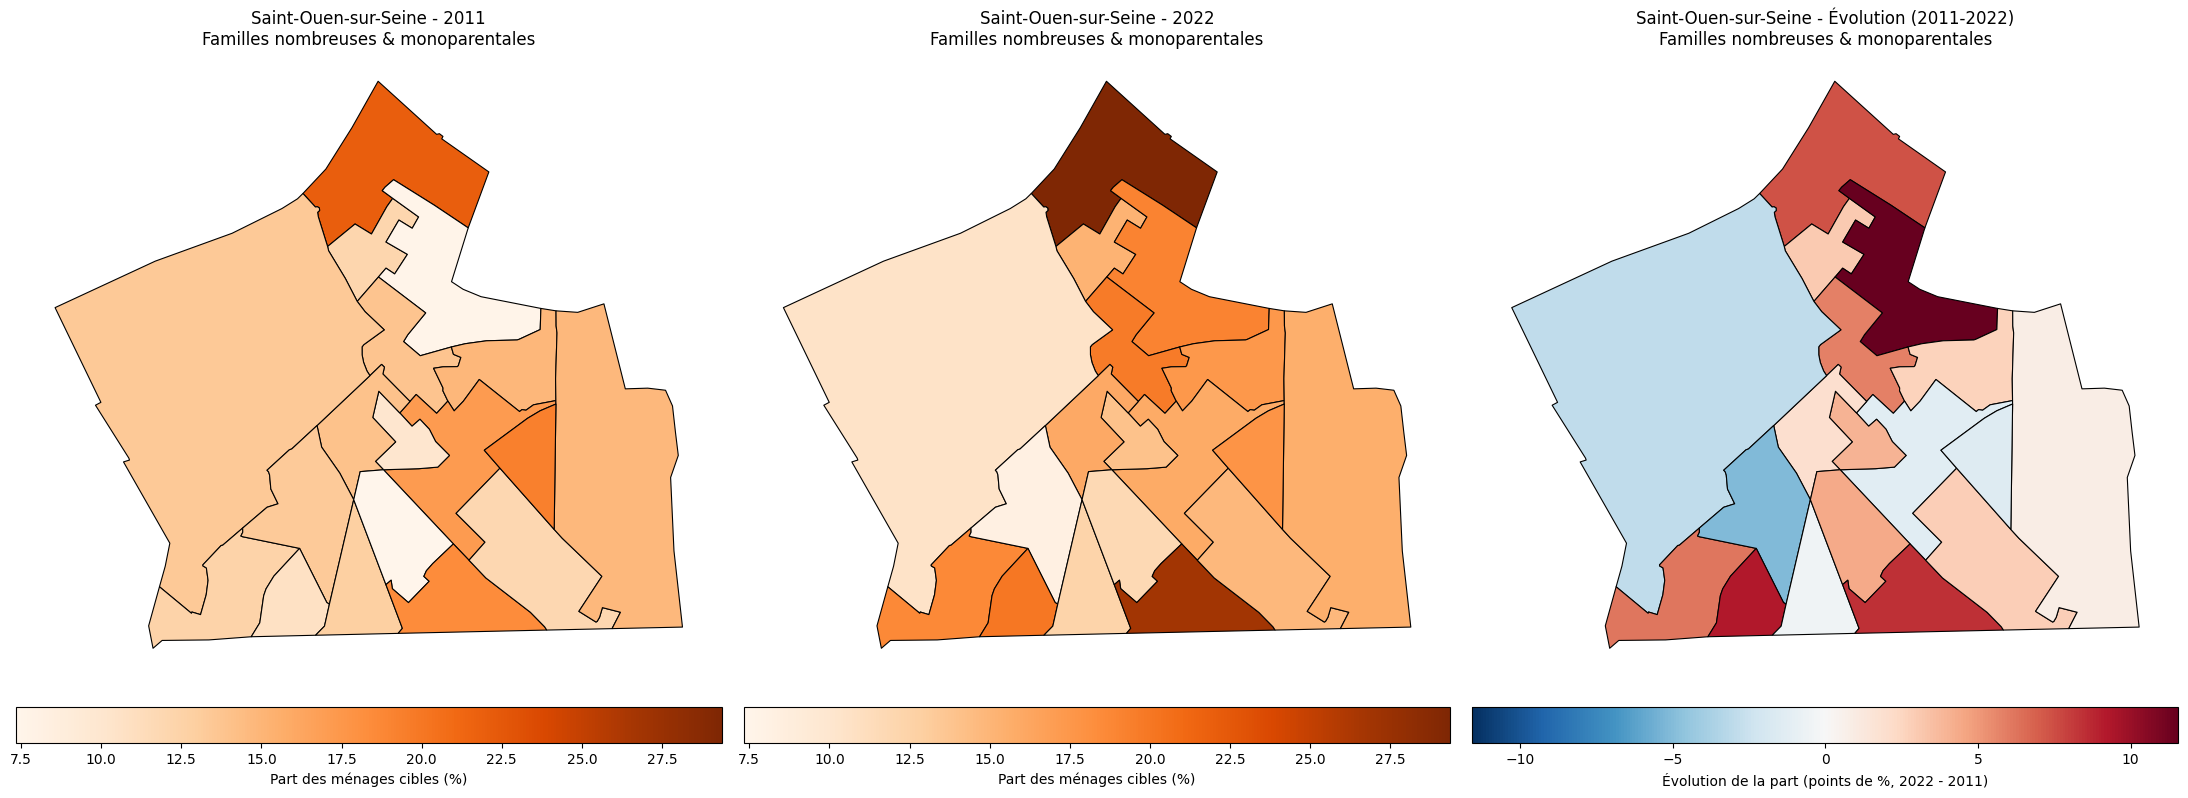

In [11]:
# ==============================================================================
# 6. ÉVOLUTION 2011 - 2022 : FAMILLES NOMBREUSES & MONOPARENTALES COMBINÉES
#    (Base INSEE : Couples - Familles - Ménages)
# ==============================================================================
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

file_cfm_2011 = (
    "C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/base-ic-couples-familles-menages-2011.xls"
)
file_cfm_2022 = (
    "C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/base-ic-couples-familles-menages-2022.xlsx"
)


def trouver_colonne(df, candidats, mots_cles_fallback=None):
  cols_upper = {str(c).upper(): c for c in df.columns}
  # 1. Recherche exacte
  for cand in candidats:
    c_up = cand.upper()
    if c_up in cols_upper:
      return cols_upper[c_up]
  # 2. Recherche partielle
  for cand in candidats:
    c_up = cand.upper()
    for up, orig in cols_upper.items():
      if c_up in up:
        return orig
  # 3. Recherche souple par mots-clés
  if mots_cles_fallback:
    for up, orig in cols_upper.items():
      if all(k.upper() in up for k in mots_cles_fallback):
        return orig
  return None


def normaliser_code_iris(serie):
  return (
      serie.astype(str)
      .str.replace(r"\.0$", "", regex=True)
      .str.strip()
      .str.zfill(9)
  )


def preparer_fonds_carte_st_ouen(gdf):
  """Garantit la présence d'une colonne 'merge_key' propre sur le GeoDataFrame."""
  out = gdf.copy()
  if "merge_key" not in out.columns:
    col_iris = trouver_colonne(
        out,
        ["CODE_IRIS", "IRIS", "ID_IRIS", "DCOMIRIS", "CODE"],
        mots_cles_fallback=["IRIS"],
    )
    if col_iris is None:
      raise KeyError(
          f"Impossible de trouver la colonne IRIS dans st_ouen_iris. Colonnes disponibles : {list(out.columns)}"
      )
    print(f"Colonne IRIS détectée dans st_ouen_iris : '{col_iris}'")
    out["merge_key"] = normaliser_code_iris(out[col_iris])
  else:
    out["merge_key"] = normaliser_code_iris(out["merge_key"])
  return out.drop_duplicates(subset=["merge_key"], keep="first")


def charger_cfm(chemin_fichier):
  df = pd.read_excel(chemin_fichier, skiprows=5)
  col_iris_cfm = trouver_colonne(
      df,
      ["IRIS", "CODE_IRIS", "COM", "GEO"],
      mots_cles_fallback=["IRIS"],
  )
  if col_iris_cfm is None:
    col_iris_cfm = df.columns[0]

  df["merge_key"] = normaliser_code_iris(df[col_iris_cfm])
  for c in df.columns:
    if c != "merge_key":
      df[c] = pd.to_numeric(df[c], errors="coerce")
  return df.drop_duplicates(subset=["merge_key"], keep="first")


def preparer_indicateur_familles_cibles(df, annee_court):
  """Calcule l'effectif et la part (%) des familles nombreuses (3+ enfants)

  et familles monoparentales combinées (sans double comptage si possible).
  """
  col_men_total = trouver_colonne(
      df,
      [f"C{annee_court}_MEN", "MEN", "P_MEN"],
      mots_cles_fallback=["MEN"],
  )
  if col_men_total is None:
    raise KeyError(
        f"Colonne total ménages introuvable pour {annee_court}. Colonnes : {list(df.columns[:15])}"
    )

  # Familles monoparentales (ménages avec famille monoparentale ou familles monoparentales)
  col_mono = trouver_colonne(
      df,
      [
          f"C{annee_court}_MENMONO",
          f"C{annee_court}_FAMMONO",
          f"P{annee_court}_FAMMONO",
          "MENMONO",
          "FAMMONO",
      ],
  )

  # Familles nombreuses : généralement 3 enfants ou plus (ou 4 enfants ou plus selon millésime)
  col_fam3p = trouver_colonne(
      df,
      [
          f"C{annee_court}_FAM3P",
          f"P{annee_court}_FAM3P",
          f"C{annee_court}_MENFAM3P",
          "FAM3P",
          "MENFAM3P",
      ],
  )
  col_fam4p = trouver_colonne(
      df,
      [
          f"C{annee_court}_FAM4P",
          f"P{annee_court}_FAM4P",
          "FAM4P",
      ],
  )

  # Si disponible, monoparentales avec 3 enfants ou plus (pour éviter de compter deux fois)
  col_mono_3p = trouver_colonne(
      df,
      [
          f"C{annee_court}_FAMMONO3P",
          f"P{annee_court}_FAMMONO3P",
          "FAMMONO3P",
      ],
  )

  print(f"--- Colonnes détectées ({annee_court}) ---")
  print(f"  Total ménages          : {col_men_total}")
  print(f"  Monoparentales         : {col_mono}")
  print(f"  Familles 3+ enfants    : {col_fam3p}")
  print(f"  Familles 4+ enfants    : {col_fam4p}")
  print(f"  Mono 3+ enfants (chev.) : {col_mono_3p}")

  eff_mono = df[col_mono].fillna(0) if col_mono else 0.0

  if col_fam3p:
    eff_nombreuses = df[col_fam3p].fillna(0)
  elif col_fam4p:
    eff_nombreuses = df[col_fam4p].fillna(0)
  else:
    eff_nombreuses = 0.0

  # Si on a les deux séries et pas la colonne d'intersection exacte,
  # on applique une borne prudente pour ne pas dépasser le total des ménages
  if col_mono and (col_fam3p or col_fam4p):
    if col_mono_3p:
      eff_chevauchement = df[col_mono_3p].fillna(0)
    else:
      # Estimation conservative de l'intersection (au plus le min des deux)
      eff_chevauchement = np.minimum(eff_mono, eff_nombreuses) * 0.25
    nb_cible = np.maximum(0.0, eff_mono + eff_nombreuses - eff_chevauchement)
  else:
    nb_cible = eff_mono + eff_nombreuses

  out = pd.DataFrame({
      "merge_key": df["merge_key"],
      "nb_cible": nb_cible,
      "nb_men_total": df[col_men_total],
  })
  out["part_cible_pct"] = (
      out["nb_cible"] / out["nb_men_total"].replace(0, np.nan)
  ) * 100
  return out


st_ouen_clean = preparer_fonds_carte_st_ouen(st_ouen_iris)
cfm_2011 = charger_cfm(file_cfm_2011)
cfm_2022 = charger_cfm(file_cfm_2022)

ind_2011 = preparer_indicateur_familles_cibles(cfm_2011, "11")
ind_2022 = preparer_indicateur_familles_cibles(cfm_2022, "22")

# Fusion avec le fonds de carte de Saint-Ouen
evol_iris = (
    st_ouen_clean[["merge_key", "geometry"]]
    .merge(
        ind_2011[["merge_key", "nb_cible", "part_cible_pct"]].rename(
            columns={"nb_cible": "nb_2011", "part_cible_pct": "part_2011"}
        ),
        on="merge_key",
        how="left",
    )
    .merge(
        ind_2022[["merge_key", "nb_cible", "part_cible_pct"]].rename(
            columns={"nb_cible": "nb_2022", "part_cible_pct": "part_2022"}
        ),
        on="merge_key",
        how="left",
    )
)

# Évolution en points de pourcentage (2022 - 2011)
evol_iris["evol_pts"] = evol_iris["part_2022"] - evol_iris["part_2011"]

print(
    f"IRIS Saint-Ouen : {len(evol_iris)} | "
    f"Sans valeur 2011 : {evol_iris['part_2011'].isna().sum()} | "
    f"Sans valeur 2022 : {evol_iris['part_2022'].isna().sum()}"
)

# Bornes communes pour les cartes 2011 et 2022
vals_parts = pd.concat(
    [evol_iris["part_2011"], evol_iris["part_2022"]], ignore_index=True
).dropna()
vmin_part = float(vals_parts.min()) if not vals_parts.empty else 0.0
vmax_part = float(vals_parts.max()) if not vals_parts.empty else 10.0
if vmin_part == vmax_part:
  vmax_part = vmin_part + 1.0

# Borne symétrique autour de 0 pour la carte d'évolution
vmax_evol = np.nanmax(np.abs(evol_iris["evol_pts"]))
vmax_evol = float(vmax_evol) if pd.notna(vmax_evol) and vmax_evol > 0 else 5.0

fig_3cartes, axes = plt.subplots(1, 3, figsize=(22, 8))

# --- Carte 1 : 2011 ---
evol_iris.plot(
    ax=axes[0],
    column="part_2011",
    cmap="Oranges",
    vmin=vmin_part,
    vmax=vmax_part,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Part des ménages cibles (%)",
        "orientation": "horizontal",
        "pad": 0.04,
    },
)
axes[0].set_title(
    "Saint-Ouen-sur-Seine - 2011\n"
    "Familles nombreuses & monoparentales",
    fontsize=12,
)
axes[0].axis("off")

# --- Carte 2 : 2022 ---
evol_iris.plot(
    ax=axes[1],
    column="part_2022",
    cmap="Oranges",
    vmin=vmin_part,
    vmax=vmax_part,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Part des ménages cibles (%)",
        "orientation": "horizontal",
        "pad": 0.04,
    },
)
axes[1].set_title(
    "Saint-Ouen-sur-Seine - 2022\n"
    "Familles nombreuses & monoparentales",
    fontsize=12,
)
axes[1].axis("off")

# --- Carte 3 : Évolution 2022 - 2011 ---
evol_iris.plot(
    ax=axes[2],
    column="evol_pts",
    cmap="RdBu_r",  # Rouge = hausse, Bleu = baisse
    vmin=-vmax_evol,
    vmax=vmax_evol,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Évolution de la part (points de %, 2022 - 2011)",
        "orientation": "horizontal",
        "pad": 0.04,
    },
)
axes[2].set_title(
    "Saint-Ouen-sur-Seine - Évolution (2011-2022)\n"
    "Familles nombreuses & monoparentales",
    fontsize=12,
)
axes[2].axis("off")

plt.tight_layout()
plt.show()

Logements commencés (93) - 2011 : 10,644
Logements commencés (93) - 2022 : 10,439
Évolution 2011 -> 2022         : -1.9 %


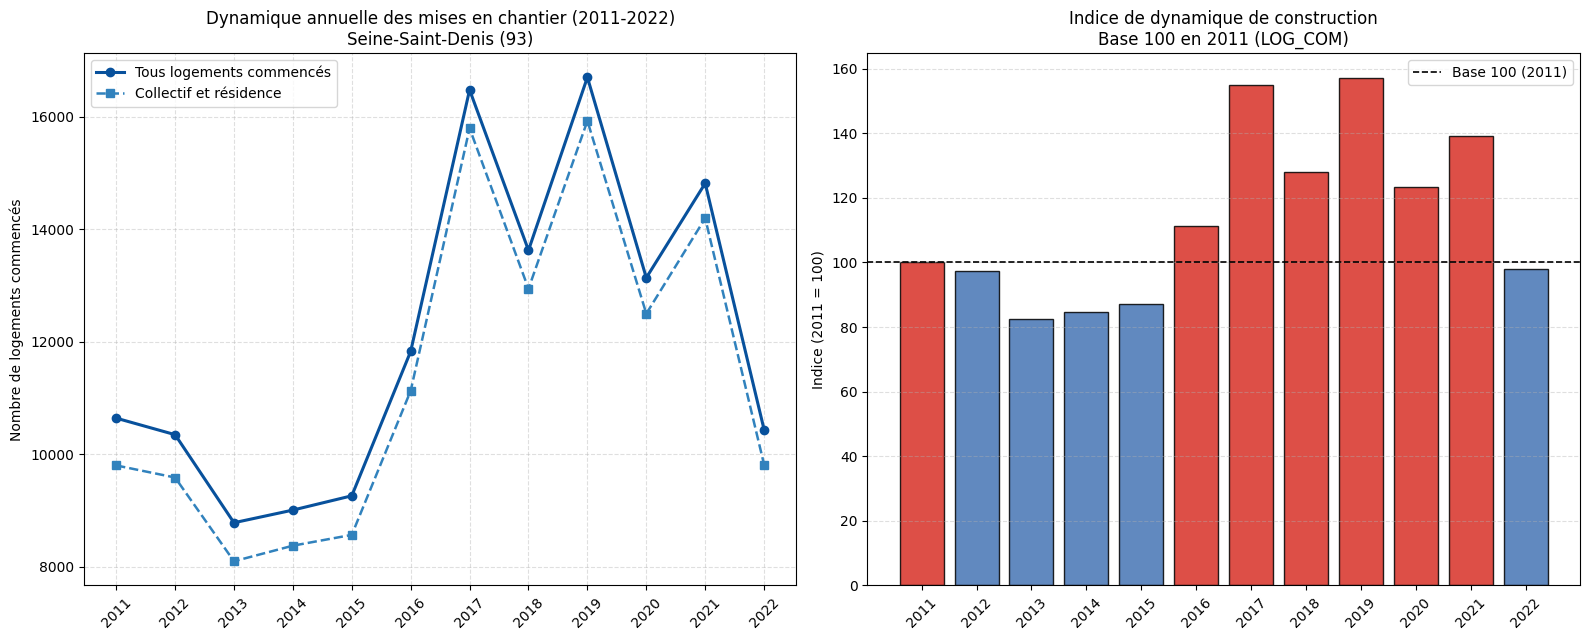

In [14]:
# ==============================================================================
# 7. DYNAMIQUE DE CONSTRUCTION (2011 - 2022) : SEINE-SAINT-DENIS (DÉPARTEMENT 93)
#    Source : Données mensuelles départementales - Logements (Sitadel)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fichier_sitadel_dept = "Donnees-mensuelles-departementales-Logements.2026-10.csv"

# 1. Chargement et filtrage sur le département 93 (Seine-Saint-Denis) et 2011-2022
df_sitadel = pd.read_csv(
    fichier_sitadel_dept, sep=";", encoding="utf-8-sig", low_memory=False
)

df_sitadel["ANNEE"] = pd.to_numeric(df_sitadel["ANNEE"], errors="coerce")
df_sitadel["MOIS"] = pd.to_numeric(df_sitadel["MOIS"], errors="coerce")
df_sitadel["DEPARTEMENT_CODE"] = (
    df_sitadel["DEPARTEMENT_CODE"].astype(str).str.strip().str.zfill(2)
)

for col in ["LOG_AUT", "LOG_COM", "SDP_AUT", "SDP_COM"]:
  df_sitadel[col] = pd.to_numeric(df_sitadel[col], errors="coerce")

df_93 = df_sitadel[
    (df_sitadel["DEPARTEMENT_CODE"] == "93")
    & (df_sitadel["ANNEE"].between(2011, 2022))
].copy()

# 2. Agrégation annuelle par type de logement
annuel_93 = (
    df_93.groupby(["ANNEE", "TYPE_LGT"], as_index=False)[
        ["LOG_AUT", "LOG_COM", "SDP_AUT", "SDP_COM"]
    ]
    .sum()
    .sort_values(["TYPE_LGT", "ANNEE"])
)

tous_log = annuel_93[annuel_93["TYPE_LGT"] == "Tous Logements"].copy()
collectif = annuel_93[annuel_93["TYPE_LGT"] == "Collectif et Residence"].copy()

# Indicateur retenu :
# - Volume annuel de logements commencés (LOG_COM)
# - Indice de dynamique base 100 en 2011 : (LOG_COM_t / LOG_COM_2011) * 100
base_2011 = tous_log.loc[tous_log["ANNEE"] == 2011, "LOG_COM"].iloc[0]
tous_log["indice_commences_b100"] = (tous_log["LOG_COM"] / base_2011) * 100

val_2011 = tous_log.loc[tous_log["ANNEE"] == 2011, "LOG_COM"].iloc[0]
val_2022 = tous_log.loc[tous_log["ANNEE"] == 2022, "LOG_COM"].iloc[0]
evol_pct = ((val_2022 - val_2011) / val_2011) * 100

print(f"Logements commencés (93) - 2011 : {val_2011:,.0f}")
print(f"Logements commencés (93) - 2022 : {val_2022:,.0f}")
print(f"Évolution 2011 -> 2022         : {evol_pct:+.1f} %")

# 3. Graphiques (2 panneaux)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Panneau 1 : Trajectoire annuelle 2011-2022 (LOG_COM)
axes[0].plot(
    tous_log["ANNEE"],
    tous_log["LOG_COM"],
    marker="o",
    linewidth=2.2,
    color="#08519c",
    label="Tous logements commencés",
)
axes[0].plot(
    collectif["ANNEE"],
    collectif["LOG_COM"],
    marker="s",
    linewidth=1.8,
    linestyle="--",
    color="#3182bd",
    label="Collectif et résidence",
)
axes[0].set_title(
    "Dynamique annuelle des mises en chantier (2011-2022)\nSeine-Saint-Denis (93)",
    fontsize=12,
)
axes[0].set_ylabel("Nombre de logements commencés")
axes[0].set_xticks(range(2011, 2023))
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# Panneau 2 : Indice de dynamique (Base 100 = 2011)
colors_evol = [
    "#d73027" if v >= 100 else "#4575b4"
    for v in tous_log["indice_commences_b100"]
]
axes[1].bar(
    tous_log["ANNEE"],
    tous_log["indice_commences_b100"],
    color=colors_evol,
    edgecolor="black",
    alpha=0.85,
)
axes[1].axhline(100, color="black", linestyle="--", linewidth=1.2, label="Base 100 (2011)")
axes[1].set_title(
    "Indice de dynamique de construction\nBase 100 en 2011 (LOG_COM)",
    fontsize=12,
)
axes[1].set_ylabel("Indice (2011 = 100)")
axes[1].set_xticks(range(2011, 2023))
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

--- Colonnes détectées (11) ---
  Ménages (MEN)               : C11_MEN
  Population des ménages (PMEN): C11_PMEN
--- Colonnes détectées (22) ---
  Ménages (MEN)               : C22_MEN
  Population des ménages (PMEN): C22_PMEN
Taille moyenne Saint-Ouen 2011 : 2.16 pers./ménage
Taille moyenne Saint-Ouen 2022 : 2.17 pers./ménage
IRIS Saint-Ouen : 18 | Sans valeur 2011 : 0 | Sans valeur 2022 : 0


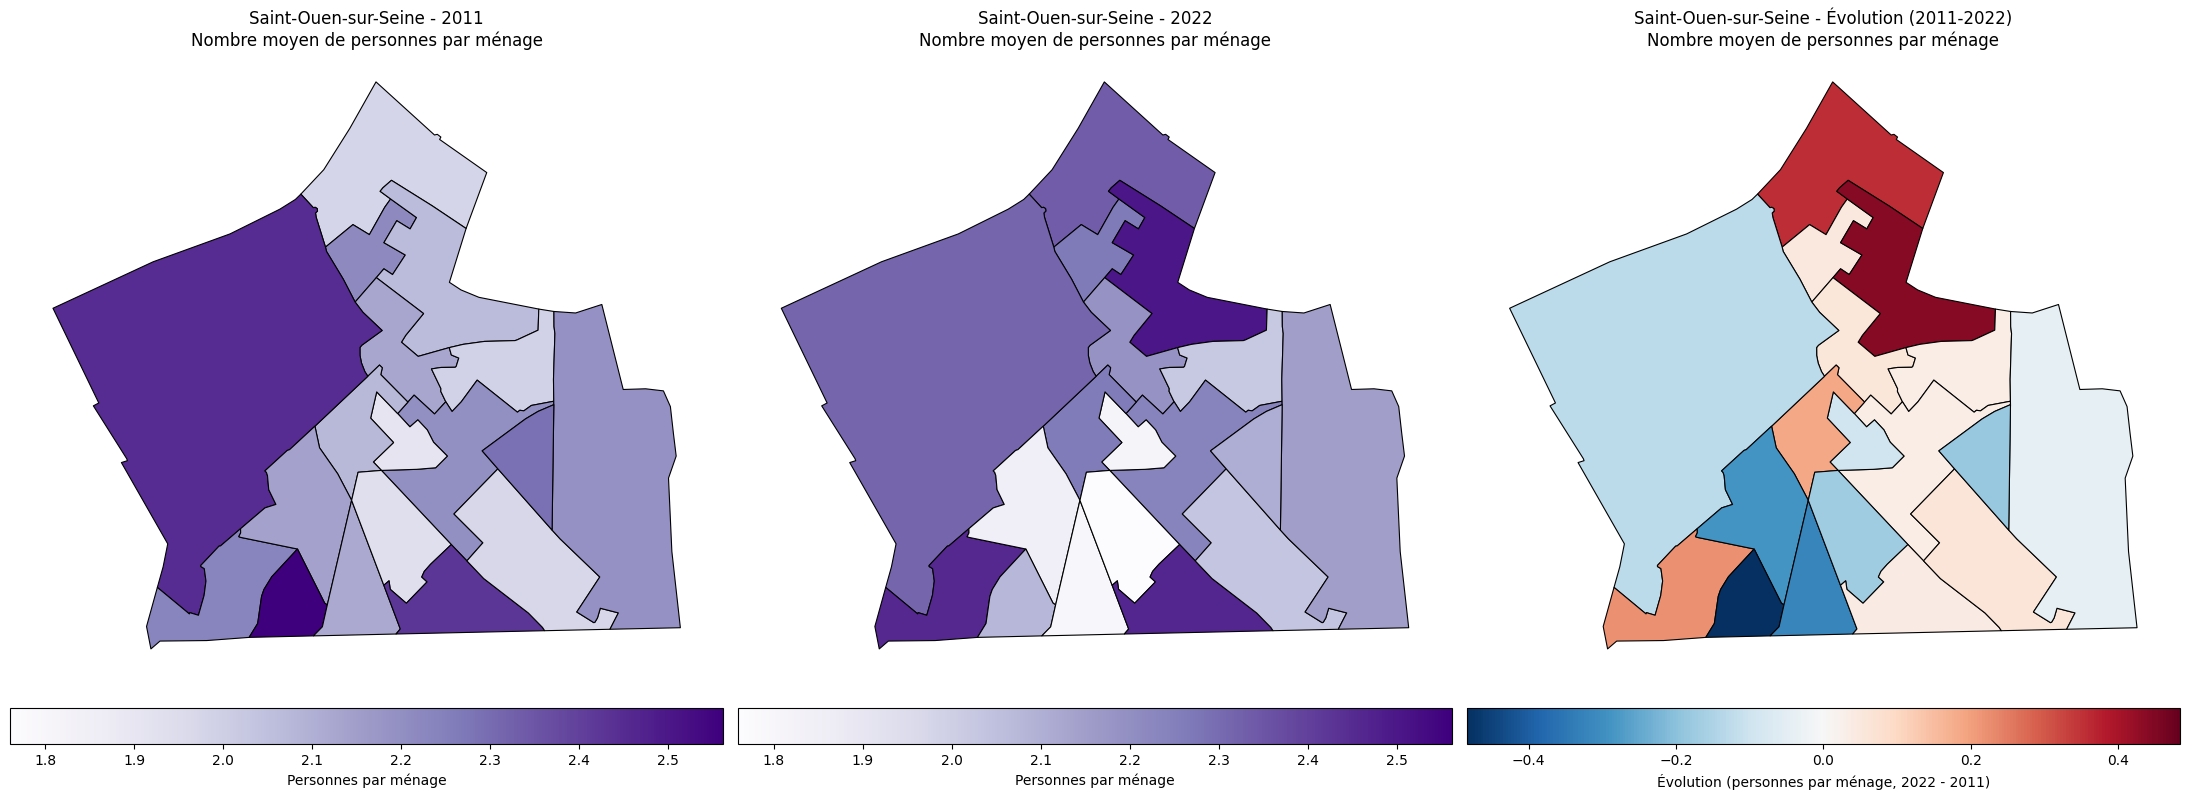

In [12]:
# ==============================================================================
# 7. ÉVOLUTION 2011 - 2022 : NOMBRE MOYEN DE PERSONNES PAR MÉNAGE
#    (Base INSEE : Couples - Familles - Ménages)
# ==============================================================================


def preparer_taille_menages(df, annee_court):
    """Calcule la taille moyenne des ménages = population des ménages / ménages."""
    col_men = trouver_colonne(
        df, [f"C{annee_court}_MEN", f"P{annee_court}_MEN", "MEN"]
    )
    col_pmen = trouver_colonne(
        df, [f"C{annee_court}_PMEN", f"P{annee_court}_PMEN", "PMEN"]
    )

    if col_men is None or col_pmen is None:
        raise KeyError(
            f"Colonnes MEN / PMEN introuvables pour {annee_court}. "
            f"Colonnes : {list(df.columns[:20])}"
        )

    print(f"--- Colonnes détectées ({annee_court}) ---")
    print(f"  Ménages (MEN)               : {col_men}")
    print(f"  Population des ménages (PMEN): {col_pmen}")

    out = pd.DataFrame({
        "merge_key": df["merge_key"],
        "nb_men": df[col_men],
        "pop_men": df[col_pmen],
    })
    out["taille_moy"] = out["pop_men"] / out["nb_men"].replace(0, np.nan)
    return out


ind_t_2011 = preparer_taille_menages(cfm_2011, "11")
ind_t_2022 = preparer_taille_menages(cfm_2022, "22")

# Taille moyenne sur l'ensemble de la commune (moyenne pondérée, pas moyenne des IRIS)
for annee, ind in [("2011", ind_t_2011), ("2022", ind_t_2022)]:
    ids_so = st_ouen_clean["merge_key"]
    sub = ind[ind["merge_key"].isin(ids_so)]
    print(f"Taille moyenne Saint-Ouen {annee} : {sub['pop_men'].sum() / sub['nb_men'].sum():.2f} pers./ménage")

# Fusion avec le fonds de carte
taille_iris = (
    st_ouen_clean[["merge_key", "geometry"]]
    .merge(
        ind_t_2011[["merge_key", "taille_moy"]].rename(columns={"taille_moy": "taille_2011"}),
        on="merge_key",
        how="left",
    )
    .merge(
        ind_t_2022[["merge_key", "taille_moy"]].rename(columns={"taille_moy": "taille_2022"}),
        on="merge_key",
        how="left",
    )
)

# Évolution en nombre de personnes par ménage (2022 - 2011)
taille_iris["evol_taille"] = taille_iris["taille_2022"] - taille_iris["taille_2011"]

print(
    f"IRIS Saint-Ouen : {len(taille_iris)} | "
    f"Sans valeur 2011 : {taille_iris['taille_2011'].isna().sum()} | "
    f"Sans valeur 2022 : {taille_iris['taille_2022'].isna().sum()}"
)

# Bornes communes pour les cartes 2011 et 2022
vals = pd.concat(
    [taille_iris["taille_2011"], taille_iris["taille_2022"]], ignore_index=True
).dropna()
vmin_t = float(vals.min()) if not vals.empty else 1.0
vmax_t = float(vals.max()) if not vals.empty else 4.0
if vmin_t == vmax_t:
    vmax_t = vmin_t + 0.1

# Borne symétrique autour de 0 pour la carte d'évolution
vmax_e = np.nanmax(np.abs(taille_iris["evol_taille"]))
vmax_e = float(vmax_e) if pd.notna(vmax_e) and vmax_e > 0 else 0.5

missing = {"color": "lightgrey", "edgecolor": "black", "hatch": "///"}

fig, axes = plt.subplots(1, 3, figsize=(22, 8))

# --- Carte 1 : 2011 ---
taille_iris.plot(
    ax=axes[0],
    column="taille_2011",
    cmap="Purples",
    vmin=vmin_t,
    vmax=vmax_t,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds=missing,
    legend_kwds={
        "label": "Personnes par ménage",
        "orientation": "horizontal",
        "pad": 0.04,
    },
)
axes[0].set_title("Saint-Ouen-sur-Seine - 2011\nNombre moyen de personnes par ménage", fontsize=12)
axes[0].axis("off")

# --- Carte 2 : 2022 ---
taille_iris.plot(
    ax=axes[1],
    column="taille_2022",
    cmap="Purples",
    vmin=vmin_t,
    vmax=vmax_t,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds=missing,
    legend_kwds={
        "label": "Personnes par ménage",
        "orientation": "horizontal",
        "pad": 0.04,
    },
)
axes[1].set_title("Saint-Ouen-sur-Seine - 2022\nNombre moyen de personnes par ménage", fontsize=12)
axes[1].axis("off")

# --- Carte 3 : Évolution 2022 - 2011 ---
taille_iris.plot(
    ax=axes[2],
    column="evol_taille",
    cmap="RdBu_r",  # Rouge = ménages plus grands, Bleu = ménages plus petits
    vmin=-vmax_e,
    vmax=vmax_e,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds=missing,
    legend_kwds={
        "label": "Évolution (personnes par ménage, 2022 - 2011)",
        "orientation": "horizontal",
        "pad": 0.04,
    },
)
axes[2].set_title("Saint-Ouen-sur-Seine - Évolution (2011-2022)\nNombre moyen de personnes par ménage", fontsize=12)
axes[2].axis("off")

plt.tight_layout()
plt.show()